In [1]:
import torch
import torch.nn as nn
torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10
# Chaque entrée contient 10 valeurs.
# La cible est la valeur immédiatement suivante.
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
# Un RNN attend : (nombre de séquences, longueur, nombre de variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : début pour apprendre, fin pour tester.
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

Text(0, 0.5, 'y')

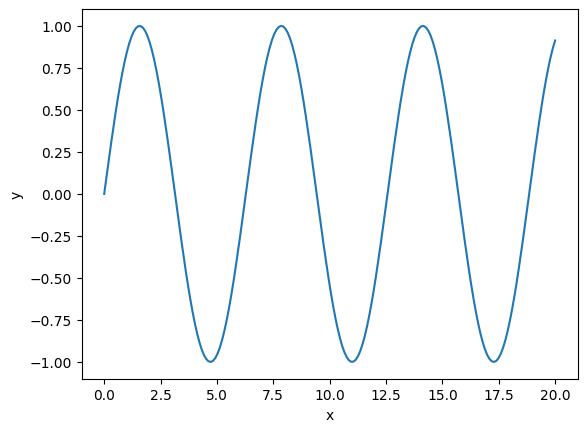

In [2]:
import matplotlib.pyplot as plt
plt.plot(periode, serie)
plt.xlabel("x")
plt.ylabel("y")

In [3]:
# --------------------------------------------------
# 2. Définir le modèle
# --------------------------------------------------

class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,     # Une valeur à chaque instant
            hidden_size=16,   # Une mémoire composée de 16 nombres
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Si aucun état initial n'est fourni, PyTorch utilise des zéros.
        etats, _ = self.rnn(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Transformer la mémoire finale en une valeur prédite.
        return self.sortie(dernier_etat)


modele = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

In [4]:
# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()  # Effacer les anciens gradients
    perte.backward()       # Calculer les nouveaux gradients
    optimiseur.step()      # Mettre à jour les paramètres

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025

Erreur de test : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


In [5]:
predictions.shape

torch.Size([40, 1])

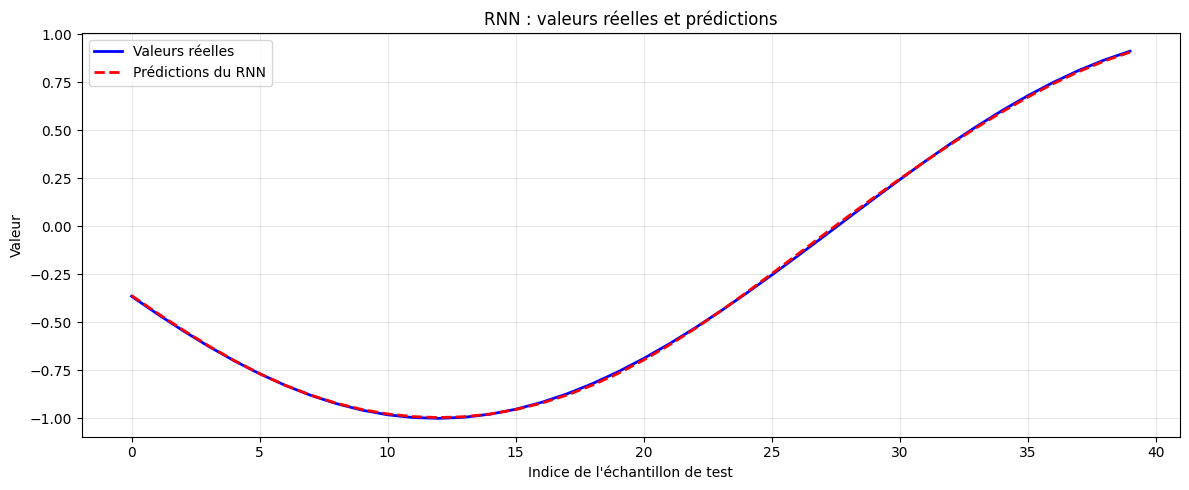

In [6]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle LSTM
# --------------------------------------------------

class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,     # Une variable à chaque instant
            hidden_size=16,   # 16 unités cachées
            num_layers=1,     # Une seule couche LSTM
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Sans états initiaux fournis, h₀ et c₀ sont mis à zéro.
        etats, (h_final, c_final) = self.lstm(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Une prédiction par séquence
        return self.sortie(dernier_etat)


modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248
Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003

Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


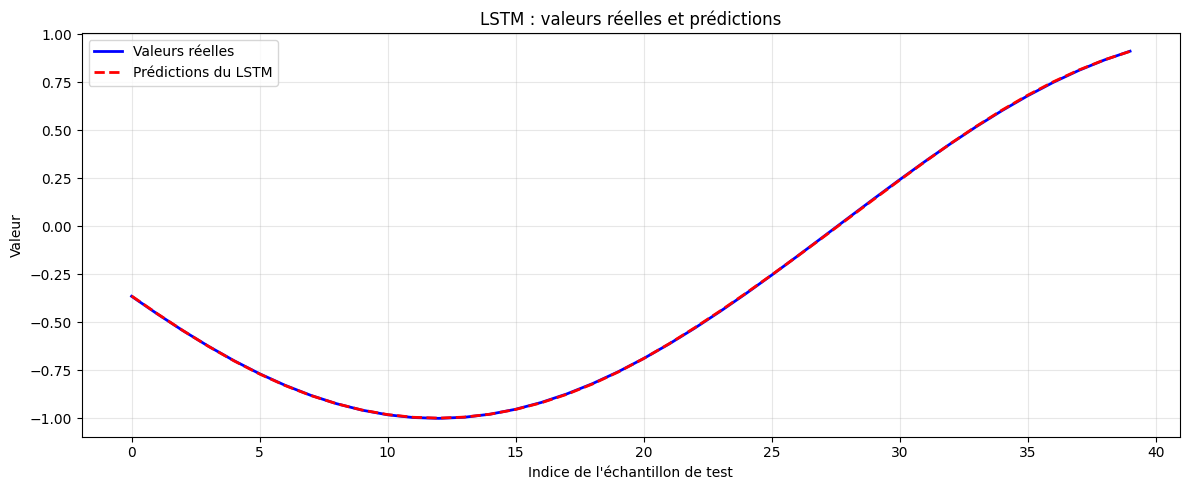

In [8]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle Transformer
# --------------------------------------------------

class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()

        dimension = 16

        # Transformer chaque valeur en un vecteur de 16 nombres.
        self.projection = nn.Linear(1, dimension)

        # Un vecteur appris pour chacune des 10 positions.
        self.positions = nn.Embedding(longueur_max, dimension)

        # Un bloc d'encodeur Transformer.
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,       # Taille des représentations : 16
            nhead=2,                 # Deux têtes d'attention
            dim_feedforward=32,      # Taille interne du réseau feed-forward
            dropout=0.0,             # Désactivé pour simplifier l'exemple
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=1
        )

        # Transformer la représentation finale en une prédiction.
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        # x : (B, 10, 1)
        longueur = x.size(1)

        # 1. Projection des valeurs
        x = self.projection(x)  # (B, 10, 16)

        # 2. Ajout de l'information de position
        indices = torch.arange(longueur, device=x.device)
        positions = self.positions(indices)  # (10, 16)

        x = x + positions.unsqueeze(0)  # (B, 10, 16)

        # 3. Mise en relation des valeurs par auto-attention
        representations = self.encodeur(x)  # (B, 10, 16)

        # 4. Récupérer la représentation de la dernière position
        derniere_position = representations[:, -1, :]  # (B, 16)

        # 5. Prédire la valeur suivante
        return self.sortie(derniere_position)  # (B, 1)


modele = MiniTransformer(longueur_max=longueur_sequence)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110
Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012
Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004

Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


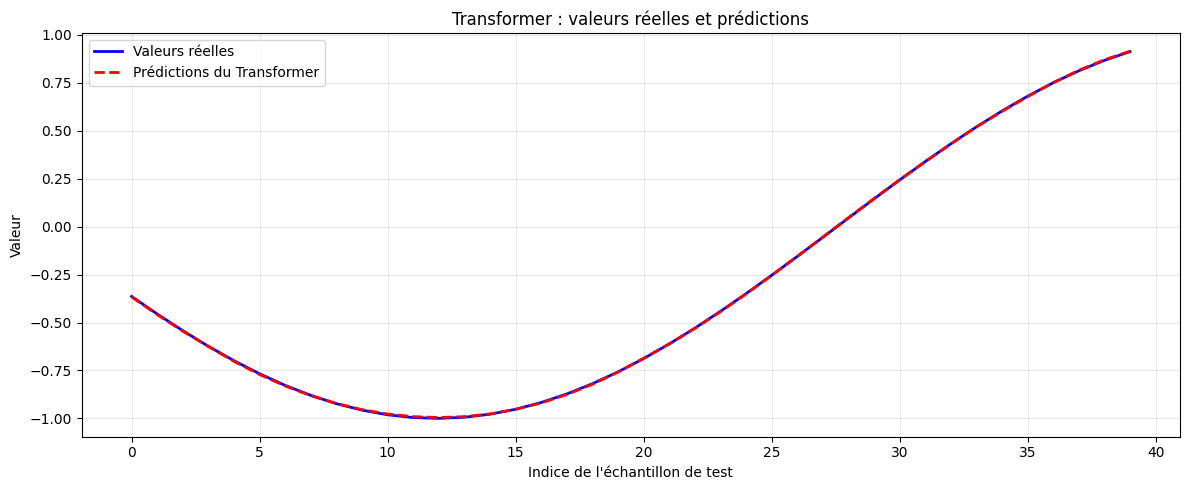

In [10]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForCausalLM.from_pretrained(nom_modele)

# GPT-2 ne possède pas de token de padding dédié.
tokenizer.pad_token = tokenizer.eos_token
modele.config.pad_token_id = tokenizer.pad_token_id

modele.eval()

# --------------------------------------------------
# 2. Transformer le texte en tokens
# --------------------------------------------------

# GPT-2 est principalement entraîné sur de l'anglais.
texte = "Artificial intelligence can help people"

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# --------------------------------------------------
# 3. Générer la suite, un token après l'autre
# --------------------------------------------------

with torch.no_grad():
    sortie = modele.generate(
        **entrees,
        max_new_tokens=50,       # Générer au maximum 50 tokens
        do_sample=True,          # Tirage aléatoire des tokens
        temperature=0.8,         # Contrôler la diversité
        top_p=0.9,               # Limiter les candidats probables
        pad_token_id=tokenizer.pad_token_id
    )

# --------------------------------------------------
# 4. Reconvertir les tokens en texte
# --------------------------------------------------

texte_genere = tokenizer.decode(
    sortie[0],
    skip_special_tokens=True
)

print("\nTexte généré :")
print(texte_genere)

W1116 17:42:35.368000 2664 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Dimensions de l'entrée : torch.Size([1, 6])

Texte généré :
Artificial intelligence can help people and organizations create jobs and build organizations, which in turn will spur growth and prosperity.

However, when a company becomes more complex, it's likely that its users will be less interested in technology. The companies that make the software that makes things


In [12]:
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForMaskedLM.from_pretrained(nom_modele)

modele.eval()

# --------------------------------------------------
# 2. Préparer un texte avec un token masqué
# --------------------------------------------------

texte = f"Rabat est la {tokenizer.mask_token} Maroc."

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Texte :", texte)
print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# Repérer la position du masque dans la séquence
position_masque = (
    entrees["input_ids"][0] == tokenizer.mask_token_id
).nonzero(as_tuple=True)[0].item()

# --------------------------------------------------
# 3. Prédire le token masqué
# --------------------------------------------------

with torch.no_grad():
    sortie = modele(**entrees)

# sortie.logits : (1, nombre de tokens, taille du vocabulaire)
scores = sortie.logits[0, position_masque, :]

# Transformer les scores en probabilités
probabilites = torch.softmax(scores, dim=-1)

# Sélectionner les 5 tokens les plus probables
top_probabilites, top_indices = torch.topk(probabilites, k=5)

# --------------------------------------------------
# 4. Afficher les propositions
# --------------------------------------------------

print("\nPropositions de BERT :")

for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer.decode([indice.item()]).strip()

    phrase = texte.replace(tokenizer.mask_token, token)

    print(f"{probabilite.item():.2%} | {phrase}")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Texte : Rabat est la [MASK] Maroc.
Dimensions de l'entrée : torch.Size([1, 8])

Propositions de BERT :
42.90% | Rabat est la capitale Maroc.
20.66% | Rabat est la du Maroc.
6.23% | Rabat est la de Maroc.
3.46% | Rabat est la ville Maroc.
1.67% | Rabat est la Rabat Maroc.


In [13]:
import os
import numpy as np
import pandas as pd

FICHIER = "household_power_consumption.txt"
DONNEES_SYNTHETIQUES = False

if not os.path.exists(FICHIER):
    DONNEES_SYNTHETIQUES = True
    rng = np.random.default_rng(0)

    # Même période et même format que le fichier UCI (une ligne par minute).
    idx = pd.date_range("2006-12-16 17:24", "2010-11-26 21:02", freq="min")
    h = (idx.hour + idx.minute / 60).to_numpy()
    jour_semaine = idx.dayofweek.to_numpy()
    jour_annee = idx.dayofyear.to_numpy()
    mois = idx.month.to_numpy()

    # Profil journalier : pic du matin, petit pic de midi, grand pic du soir.
    profil = (0.35
              + 0.9 * np.exp(-0.5 * ((h - 7.5) / 1.3) ** 2)
              + 0.4 * np.exp(-0.5 * ((h - 13.0) / 2.0) ** 2)
              + 1.4 * np.exp(-0.5 * ((h - 20.5) / 2.0) ** 2))
    profil *= 1 + 0.30 * (jour_semaine >= 5) * np.exp(-0.5 * ((h - 11.0) / 4.0) ** 2)
    profil *= 1 + 0.35 * np.cos(2 * np.pi * (jour_annee - 15) / 365)   # hiver plus élevé
    profil *= np.where(mois == 8, 0.55, 1.0)                           # vacances d'août

    # Bruit : composante lente par heure (AR(1)) + bruit minute par minute.
    nb_heures = len(idx) // 60 + 2
    ar = np.zeros(nb_heures)
    for t in range(1, nb_heures):
        ar[t] = 0.6 * ar[t - 1] + rng.normal(0, 0.25)
    lent = np.exp(ar[np.arange(len(idx)) // 60] - 0.04)
    minute = rng.lognormal(0, 0.18, len(idx))
    pics = 1 + (rng.random(len(idx)) < 0.002) * rng.exponential(2.0, len(idx))
    gap = np.clip(profil * lent * minute * pics, 0.08, 10.0)

    # Valeurs manquantes : petites coupures + une longue panne.
    manquant = np.zeros(len(idx), dtype=bool)
    for debut in rng.integers(0, len(idx), 400):
        manquant[debut:debut + rng.integers(1, 180)] = True
    manquant[600_000:640_000] = True

    def fmt(a, nd):
        s = np.char.mod(f"%.{nd}f", a)
        return np.where(manquant, "?", s)

    synth = pd.DataFrame({
        "Date": idx.strftime("%d/%m/%Y"),
        "Time": idx.strftime("%H:%M:%S"),
        "Global_active_power": fmt(gap, 3),
        "Global_reactive_power": fmt(gap * 0.1, 3),
        "Voltage": fmt(240 + rng.normal(0, 2, len(idx)), 2),
        "Global_intensity": fmt(gap * 4.2, 1),
        "Sub_metering_1": fmt(np.zeros(len(idx)), 1),
        "Sub_metering_2": fmt(np.zeros(len(idx)), 1),
        "Sub_metering_3": fmt(np.zeros(len(idx)), 1),
    })
    synth.to_csv(FICHIER, sep=";", index=False)
    print("=" * 78)
    print("ATTENTION : household_power_consumption.txt est introuvable.")
    print("Un fichier SYNTHETIQUE au même format vient d'être généré pour tester le code.")
    print("Les résultats ci-dessous NE SONT PAS ceux du vrai jeu de données UCI.")
    print("=" * 78)
else:
    print("Fichier réel trouvé :", FICHIER)

ATTENTION : household_power_consumption.txt est introuvable.
Un fichier SYNTHETIQUE au même format vient d'être généré pour tester le code.
Les résultats ci-dessous NE SONT PAS ceux du vrai jeu de données UCI.


In [14]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False,
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

# Puissance moyenne horaire : conserver les heures suffisamment renseignées.
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

# Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test.
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Normalisation calculée uniquement sur l'entraînement.
moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

# Une entrée contient 24 heures consécutives.
# Écarter les fenêtres comportant des valeurs manquantes.
fenetre = 24
X, y, dates_cibles = [], [], []

for i in range(fenetre, n):
    sequence = valeurs[i - fenetre:i]
    cible = valeurs[i]

    if np.isfinite(sequence).all() and np.isfinite(cible):
        X.append(sequence)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
dates_cibles = np.array(dates_cibles)

train_mask = dates_cibles < fin_train
val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
test_mask = dates_cibles >= fin_val

train_loader = DataLoader(
    TensorDataset(X[train_mask], y[train_mask]),
    batch_size=64,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(X[val_mask], y[val_mask]),
    batch_size=64,
)
test_loader = DataLoader(
    TensorDataset(X[test_mask], y[test_mask]),
    batch_size=64,
)

In [15]:
print(f"Heures au total        : {n}")
print(f"Heures valides         : {int(serie.notna().sum())}  (>= 45 minutes renseignées)")
print(f"Moyenne / écart-type   : {moyenne:.3f} kW / {ecart_type:.3f} kW  (calculés sur l'entraînement)")
print(f"X : {tuple(X.shape)} | y : {tuple(y.shape)}")
print(f"Fenêtres train / val / test : {int(train_mask.sum())} / {int(val_mask.sum())} / {int(test_mask.sum())}")

Heures au total        : 34589
Heures valides         : 33186  (>= 45 minutes renseignées)
Moyenne / écart-type   : 0.851 kW / 0.574 kW  (calculés sur l'entraînement)
X : (25776, 24, 1) | y : (25776, 1)
Fenêtres train / val / test : 17422 / 4154 / 4200


In [16]:
import math, copy, time
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class EncodagePositionnel(nn.Module):
    """Encodage positionnel sinusoïdal : une signature par position (heure de la fenêtre)."""
    def __init__(self, d_model, longueur_max=512):
        super().__init__()
        position = torch.arange(longueur_max).unsqueeze(1)
        diviseur = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(longueur_max, d_model)
        pe[:, 0::2] = torch.sin(position * diviseur)
        pe[:, 1::2] = torch.cos(position * diviseur)
        self.register_buffer("pe", pe.unsqueeze(0))     # (1, longueur_max, d_model)

    def forward(self, x):                                # x : (B, L, d_model)
        return x + self.pe[:, : x.size(1)]


class EnergyTransformer(nn.Module):
    def __init__(self, d_model=32, nhead=4, dim_feedforward=128, dropout=0.1,
                 nb_couches=2, longueur_max=512):
        super().__init__()
        self.projection = nn.Linear(1, d_model)
        self.position = EncodagePositionnel(d_model, longueur_max)
        couche = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=nb_couches,
                                              enable_nested_tensor=False)
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x):                                # (B, 24, 1)
        h = self.projection(x)                           # (B, 24, 32)
        h = self.position(h)                             # (B, 24, 32)
        h = self.encodeur(h)                             # (B, 24, 32)
        return self.sortie(h[:, -1, :])                  # dernière heure -> (B, 1)


modele = EnergyTransformer().to(device)

# Vérification des formes demandées
xb, yb = next(iter(train_loader))
with torch.no_grad():
    h = modele.projection(xb.to(device))
    print("Entrée                    :", tuple(xb.shape))
    print("Après projection          :", tuple(h.shape))
    print("Après Transformer Encoder :", tuple(modele.encodeur(modele.position(h)).shape))
    print("Prédiction                :", tuple(modele(xb.to(device)).shape))
print("Nombre de paramètres      :", sum(p.numel() for p in modele.parameters()))

Entrée                    : (64, 24, 1)
Après projection          : (64, 24, 32)
Après Transformer Encoder : (64, 24, 32)
Prédiction                : (64, 1)
Nombre de paramètres      : 25505


Epoque  1 | train 0.2024 | val 0.2325  <- meilleur
Epoque  2 | train 0.1471 | val 0.1855  <- meilleur
Epoque  3 | train 0.1325 | val 0.1716  <- meilleur
Epoque  4 | train 0.1200 | val 0.1651  <- meilleur
Epoque  5 | train 0.1150 | val 0.1995
Epoque  6 | train 0.1135 | val 0.1548  <- meilleur
Epoque  7 | train 0.1107 | val 0.1519  <- meilleur
Epoque  8 | train 0.1100 | val 0.1570
Epoque  9 | train 0.1091 | val 0.1429  <- meilleur
Epoque 10 | train 0.1077 | val 0.1431
Epoque 11 | train 0.1032 | val 0.1502
Epoque 12 | train 0.1061 | val 0.1569
Epoque 13 | train 0.1041 | val 0.1472
Epoque 14 | train 0.1024 | val 0.1435
Epoque 15 | train 0.1030 | val 0.1462
Epoque 16 | train 0.1006 | val 0.1473
Epoque 17 | train 0.1007 | val 0.1567
Epoque 18 | train 0.1016 | val 0.1463
Epoque 19 | train 0.0990 | val 0.1412  <- meilleur
Epoque 20 | train 0.0984 | val 0.1411  <- meilleur

Meilleure époque (perte de validation) : 20 | durée : 202 s


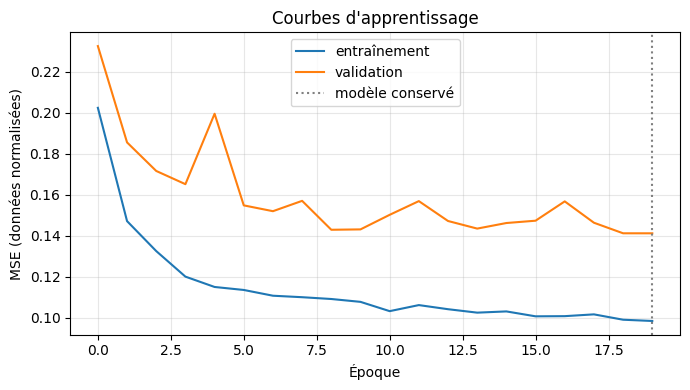

In [17]:
def entrainer(modele, train_loader, val_loader, epoques=20, lr=1e-3, verbeux=True):
    """Adam + MSE, au plus `epoques` époques, on garde le modèle de meilleure perte de validation."""
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    historique = {"train": [], "val": []}
    meilleure_val, meilleur_etat, meilleure_epoque = float("inf"), None, 0

    for epoque in range(1, epoques + 1):
        modele.train()
        somme, total = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            perte = critere(modele(xb), yb)
            optimiseur.zero_grad()
            perte.backward()
            optimiseur.step()
            somme += perte.item() * len(xb)
            total += len(xb)
        perte_train = somme / total

        modele.eval()
        somme, total = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                somme += critere(modele(xb), yb).item() * len(xb)
                total += len(xb)
        perte_val = somme / total

        historique["train"].append(perte_train)
        historique["val"].append(perte_val)
        if perte_val < meilleure_val:
            meilleure_val, meilleur_etat, meilleure_epoque = perte_val, copy.deepcopy(modele.state_dict()), epoque
        if verbeux:
            marque = "  <- meilleur" if epoque == meilleure_epoque else ""
            print(f"Epoque {epoque:2d} | train {perte_train:.4f} | val {perte_val:.4f}{marque}")

    modele.load_state_dict(meilleur_etat)
    return historique, meilleure_epoque


debut = time.time()
historique, meilleure_epoque = entrainer(modele, train_loader, val_loader, epoques=20, lr=1e-3)
print(f"\nMeilleure époque (perte de validation) : {meilleure_epoque} | durée : {time.time() - debut:.0f} s")

plt.figure(figsize=(7, 4))
plt.plot(historique["train"], label="entraînement")
plt.plot(historique["val"], label="validation")
plt.axvline(meilleure_epoque - 1, color="gray", linestyle=":", label="modèle conservé")
plt.xlabel("Époque"); plt.ylabel("MSE (données normalisées)")
plt.title("Courbes d'apprentissage"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [18]:
def predire(modele, loader):
    modele.eval()
    sorties = []
    with torch.no_grad():
        for xb, _ in loader:
            sorties.append(modele(xb.to(device)).cpu())
    return torch.cat(sorties).squeeze(-1).numpy()


def en_kw(valeurs_normalisees):
    """Retour à l'échelle d'origine (kW)."""
    return valeurs_normalisees * ecart_type + moyenne


def mae(a, b):
    return float(np.mean(np.abs(a - b)))


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


X_test = X[test_mask]
y_test_kw = en_kw(y[test_mask].squeeze(-1).numpy())
pred_transformer = en_kw(predire(modele, test_loader))
pred_persistance = en_kw(X_test[:, -1, 0].numpy())   # dernière heure observée
pred_journaliere = en_kw(X_test[:, 0, 0].numpy())    # valeur 24 h avant l'heure cible

resultats = pd.DataFrame(
    {
        "MAE (kW)": [mae(p, y_test_kw) for p in (pred_transformer, pred_persistance, pred_journaliere)],
        "RMSE (kW)": [rmse(p, y_test_kw) for p in (pred_transformer, pred_persistance, pred_journaliere)],
    },
    index=["Transformer", "Persistance (t-1)", "Référence journalière (t-24)"],
).round(4)
print(f"Évaluation sur {len(y_test_kw)} heures de test")
resultats

Évaluation sur 4200 heures de test


,MAE (kW),RMSE (kW)
Transformer,0.1045,0.1520
Persistance (t-1),0.1839,0.2636
Référence journalière (t-24),0.2282,0.3378


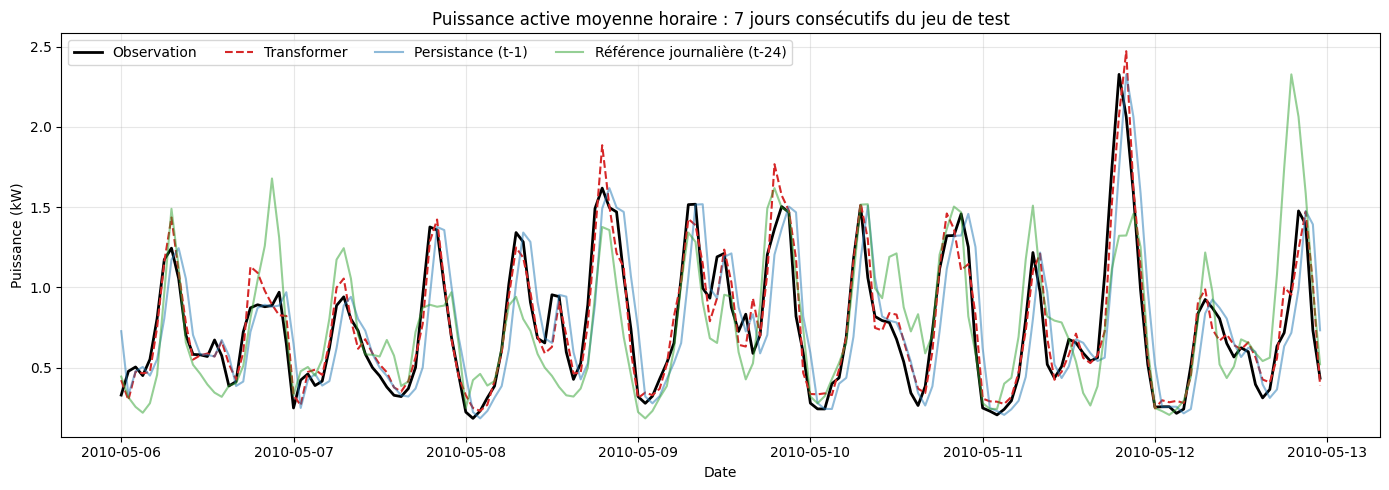

In [19]:
# Sept jours consécutifs (168 heures sans trou) dans le jeu de test
indices_test = dates_cibles[test_mask]
sans_trou = np.diff(indices_test) == 1
fenetres_ok = np.convolve(sans_trou, np.ones(167, dtype=int), mode="valid") == 167
debut_7j = int(np.argmax(fenetres_ok))
sel = slice(debut_7j, debut_7j + 168)
heures = serie.index[indices_test[sel]]

plt.figure(figsize=(14, 5))
plt.plot(heures, y_test_kw[sel], label="Observation", color="black", linewidth=2)
plt.plot(heures, pred_transformer[sel], label="Transformer", color="tab:red", linestyle="--")
plt.plot(heures, pred_persistance[sel], label="Persistance (t-1)", color="tab:blue", alpha=0.5)
plt.plot(heures, pred_journaliere[sel], label="Référence journalière (t-24)", color="tab:green", alpha=0.5)
plt.title("Puissance active moyenne horaire : 7 jours consécutifs du jeu de test")
plt.xlabel("Date"); plt.ylabel("Puissance (kW)")
plt.legend(ncol=4); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [20]:
# Question 1 : le Transformer améliore-t-il les deux références ?
m_t, r_t = mae(pred_transformer, y_test_kw), rmse(pred_transformer, y_test_kw)
for nom, p in [("la persistance", pred_persistance), ("la référence journalière", pred_journaliere)]:
    m_b, r_b = mae(p, y_test_kw), rmse(p, y_test_kw)
    gain_mae, gain_rmse = 100 * (1 - m_t / m_b), 100 * (1 - r_t / r_b)
    verdict = "améliore" if (m_t < m_b and r_t < r_b) else "n'améliore PAS (sur les deux métriques)"
    print(f"Le Transformer {verdict} {nom} : MAE {gain_mae:+.1f} % | RMSE {gain_rmse:+.1f} %")
if DONNEES_SYNTHETIQUES:
    print("\n(!) Ces conclusions portent sur des données SYNTHETIQUES : à refaire avec le vrai fichier.")

Le Transformer améliore la persistance : MAE +43.1 % | RMSE +42.3 %
Le Transformer améliore la référence journalière : MAE +54.2 % | RMSE +55.0 %

(!) Ces conclusions portent sur des données SYNTHETIQUES : à refaire avec le vrai fichier.


In [21]:
# Question 2 : fenêtre de 168 heures (une semaine) au lieu de 24 heures
from numpy.lib.stride_tricks import sliding_window_view


def preparer_fenetre(fenetre, taille_lot=64):
    """Même préparation que plus haut, pour une longueur de fenêtre quelconque."""
    blocs = sliding_window_view(valeurs, fenetre + 1)      # ligne j : indices j .. j+fenetre
    entrees, cibles = blocs[:, :-1], blocs[:, -1]
    indices = np.arange(fenetre, n)                        # indice de l'heure cible
    valide = np.isfinite(blocs).all(axis=1)
    entrees, cibles, indices = entrees[valide], cibles[valide], indices[valide]
    Xf = torch.tensor(entrees.copy(), dtype=torch.float32).unsqueeze(-1)
    yf = torch.tensor(cibles.copy(), dtype=torch.float32).unsqueeze(-1)
    m_tr, m_va, m_te = indices < fin_train, (indices >= fin_train) & (indices < fin_val), indices >= fin_val
    chargeur = lambda m, melange: DataLoader(TensorDataset(Xf[m], yf[m]), batch_size=taille_lot, shuffle=melange)
    return chargeur(m_tr, True), chargeur(m_va, False), chargeur(m_te, False), indices[m_te]


torch.manual_seed(42)
train168, val168, test168, indices_test168 = preparer_fenetre(168)
modele168 = EnergyTransformer(longueur_max=168).to(device)

debut = time.time()
hist168, meilleure168 = entrainer(modele168, train168, val168, epoques=20, lr=1e-3, verbeux=False)
print(f"Fenêtre 168 h : entraînée en {time.time() - debut:.0f} s (meilleure époque : {meilleure168})")

pred168 = en_kw(predire(modele168, test168))

# Comparaison équitable : uniquement les heures cibles disponibles pour les DEUX modèles
y_complet = np.full(n, np.nan); y_complet[dates_cibles[test_mask]] = y_test_kw
p24_complet = np.full(n, np.nan); p24_complet[dates_cibles[test_mask]] = pred_transformer
p168_complet = np.full(n, np.nan); p168_complet[indices_test168] = pred168
commun = np.isfinite(p24_complet) & np.isfinite(p168_complet)

tableau = pd.DataFrame(
    {
        "MAE (kW)": [mae(p24_complet[commun], y_complet[commun]), mae(p168_complet[commun], y_complet[commun])],
        "RMSE (kW)": [rmse(p24_complet[commun], y_complet[commun]), rmse(p168_complet[commun], y_complet[commun])],
    },
    index=["Transformer, fenêtre 24 h", "Transformer, fenêtre 168 h"],
).round(4)
print(f"Comparaison sur {int(commun.sum())} heures de test communes")
tableau

Fenêtre 168 h : entraînée en 457 s (meilleure époque : 19)
Comparaison sur 1464 heures de test communes


,MAE (kW),RMSE (kW)
"Transformer, fenêtre 24 h",0.1105,0.163
"Transformer, fenêtre 168 h",0.1218,0.175


In [22]:
m24, r24 = tableau.iloc[0]
m168, r168 = tableau.iloc[1]
print(f"MAE  : {m24:.4f} -> {m168:.4f} kW ({100 * (1 - m168 / m24):+.1f} %)")
print(f"RMSE : {r24:.4f} -> {r168:.4f} kW ({100 * (1 - r168 / r24):+.1f} %)")
print("Verdict :", "la fenêtre de 168 h fait mieux sur les deux métriques."
      if (m168 < m24 and r168 < r24) else
      "pas d'amélioration nette avec 168 h dans cette expérience.")
if DONNEES_SYNTHETIQUES:
    print("(!) Données SYNTHETIQUES : conclusion à refaire avec le vrai fichier.")

MAE  : 0.1105 -> 0.1218 kW (-10.2 %)
RMSE : 0.1630 -> 0.1750 kW (-7.4 %)
Verdict : pas d'amélioration nette avec 168 h dans cette expérience.
(!) Données SYNTHETIQUES : conclusion à refaire avec le vrai fichier.


In [23]:
# Création du fichier corpus.txt (texte original rédigé pour ce TP, environ 5723 caractères).
# Si vous avez votre propre corpus.txt, supprimez cette cellule : il sera utilisé tel quel.
import os

if not os.path.exists("corpus.txt"):
    CORPUS = """Le matin, la ville de Casablanca s'éveille doucement. Les boutiques ouvrent leurs rideaux, les premiers tramways traversent les grandes avenues et l'odeur du pain chaud se mêle à celle du café. Sur la corniche, des coureurs saluent l'océan avant de rentrer travailler. Chaque jour ressemble au précédent, et pourtant rien n'est jamais tout à fait pareil.

Samir est étudiant en dernière année d'école d'ingénieurs. Il passe ses journées entre les cours, les travaux pratiques et les projets de fin d'études. Le soir, il aime s'installer à la bibliothèque avec son ordinateur portable et une tasse de thé à la menthe. Il lit des articles, essaie des idées, corrige ses erreurs et recommence. Il sait que l'on apprend surtout en pratiquant.

Un réseau de neurones est un programme qui apprend à partir d'exemples. On lui montre des entrées et les réponses attendues, puis on mesure l'écart entre ce qu'il prédit et ce qu'il devrait prédire. Cet écart s'appelle la perte. À chaque étape, on modifie légèrement les paramètres du réseau pour que la perte diminue. Après des milliers de petites corrections, le modèle finit par généraliser.

Avant les Transformers, les réseaux récurrents lisaient les textes mot après mot. Ils gardaient une mémoire de ce qu'ils avaient lu, mais cette mémoire s'effaçait peu à peu. Quand la phrase était longue, le début était presque oublié à la fin. De plus, il fallait attendre la fin d'un calcul pour commencer le suivant, ce qui rendait l'entraînement lent.

L'attention a changé la manière de lire une séquence. Au lieu de résumer le passé dans un seul vecteur, le modèle regarde tous les mots à la fois et décide lesquels sont importants pour comprendre le mot courant. Chaque mot pose une question, chaque mot propose une réponse, et les réponses les plus pertinentes reçoivent le plus de poids. C'est comme chercher une information dans un livre en posant la bonne question à chaque page.

Dans un modèle de type GPT, un mot ne peut regarder que les mots qui le précèdent. On cache le futur avec un masque, car le but est de deviner la suite. Si le modèle pouvait lire la réponse, il n'aurait rien à apprendre et il serait incapable d'écrire quoi que ce soit de nouveau. Le texte est donc produit un caractère après l'autre, chaque caractère choisi dépendant de tous ceux qui ont été écrits avant lui.

Dans un modèle de type BERT, au contraire, le texte est lu dans les deux sens. On cache quelques mots au hasard et le modèle doit les retrouver grâce aux mots situés à gauche et à droite. Cette lecture complète donne de très bonnes représentations pour comprendre le sens d'une phrase, classer un avis ou répondre à une question, mais elle ne permet pas d'écrire un texte de gauche à droite.

La température règle le courage du modèle au moment d'écrire. Avec une température basse, il choisit presque toujours la lettre la plus probable et ses phrases deviennent prudentes, parfois répétitives. Avec une température élevée, il ose des lettres improbables, et le texte devient plus varié mais aussi plus confus. Il faut trouver un équilibre entre la sécurité et la créativité.

Le vendredi après-midi, Samir retrouve ses amis dans un petit café près de l'école. Ils parlent de leurs projets, de leurs stages et des examens qui approchent. Nadia prépare un système de recommandation, Youssef travaille sur la reconnaissance d'images et Salma rédige un rapport sur la prévision de la consommation d'énergie. Chacun écoute les autres, pose des questions et propose des idées.

La consommation d'électricité d'une maison suit le rythme de la vie de ses habitants. Elle est faible la nuit, monte le matin quand tout le monde se prépare, redescend pendant la journée, puis atteint un pic le soir au moment du repas. Le week-end, les habitudes changent, et en hiver le chauffage fait grimper la courbe. Un bon modèle doit apprendre ces régularités sans les confondre avec le hasard.

Le soleil se couche sur l'Atlantique et la lumière devient orange. Les pêcheurs rentrent au port, les enfants jouent sur la plage et les cafés se remplissent. Samir ferme son ordinateur, range ses notes et marche un moment au bord de l'eau. Demain, il testera une nouvelle idée. Si elle échoue, il comprendra pourquoi, et il essaiera encore.

Apprendre à programmer demande de la patience. Au début, une simple virgule oubliée peut bloquer un programme pendant une heure. Puis, peu à peu, on reconnaît les erreurs, on lit les messages avec attention et on découvre que les machines sont plus logiques que mystérieuses. La curiosité reste le meilleur outil d'un ingénieur, et la rigueur sa meilleure habitude.

Pour savoir si un modèle est bon, on ne le juge jamais sur les données qui ont servi à l'entraîner. On garde de côté une partie du texte, ou de la série, que le modèle n'a jamais vue. Si les résultats restent bons sur ces nouvelles données, alors le modèle a vraiment appris quelque chose. Sinon, il a seulement mémorisé ses exemples, comme un élève qui récite sa leçon sans la comprendre.

Les mots ne sont que des symboles, mais ils portent des idées. Un modèle de langage ne connaît ni la mer, ni le thé, ni la fatigue d'une longue journée, et pourtant il apprend à manipuler ces mots avec une surprenante aisance, simplement parce qu'ils apparaissent toujours dans les mêmes contextes. Comprendre ce que cela signifie réellement est l'une des grandes questions de notre époque.

Ce soir, la bibliothèque ferme à vingt heures. Samir sort le dernier, salue le gardien et prend le chemin de la maison. Dans sa tête, les formes des tenseurs défilent encore : le lot, la longueur, la dimension. Il sourit en pensant que, demain matin, la ville s'éveillera de nouveau et que le cycle recommencera."""
    with open("corpus.txt", "w", encoding="utf-8") as fichier:
        fichier.write(CORPUS)
    print("corpus.txt créé.")
else:
    print("corpus.txt déjà présent : conservé.")

corpus.txt créé.


In [24]:
import torch

with open("corpus.txt", encoding="utf-8") as fichier:
    texte = fichier.read()

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)

# Exemple d'une paire entrée/cible
longueur = 64
x = tokens[:longueur]
y = tokens[1:longueur + 1]

In [25]:
print("Nombre de caractères :", len(texte))
print("Taille du vocabulaire :", len(caracteres))
print("Caractères              :", "".join(caracteres).replace("\n", "\\n"))
print("x (ids)  :", tuple(x.shape), "| y (ids) :", tuple(y.shape))
print("x décodé :", repr("".join(itos[i] for i in x[:25].tolist())))
print("y décodé :", repr("".join(itos[i] for i in y[:25].tolist())), " (décalé d'un caractère)")

Nombre de caractères : 5722
Taille du vocabulaire : 58
Caractères              : \n ',-.:ABCDEGILNOPQRSTUYabcdefghijklmnopqrstuvwxyÀàâçèéêîô
x (ids)  : (64,) | y (ids) : (64,)
x décodé : 'Le matin, la ville de Cas'
y décodé : 'e matin, la ville de Casa'  (décalé d'un caractère)


In [26]:
T = x.shape[-1]

# True signifie : cette relation d'attention est interdite
masque = torch.triu(
    torch.ones(T, T, dtype=torch.bool, device=x.device),
    diagonal=1,
)

In [27]:
import math, copy, time
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

taille_vocab = len(caracteres)
longueur = 64          # taille du contexte (déjà définie plus haut)


class BlocGPT(nn.Module):
    """Bloc pré-norme : LN -> attention causale -> résidu -> LN -> MLP -> résidu."""
    def __init__(self, d_model=64, nhead=4, dim_mlp=256, dropout=0.2, causal=True):
        super().__init__()
        self.causal = causal
        self.ln1 = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, dim_mlp),     # 64 -> 256
            nn.GELU(),
            nn.Linear(dim_mlp, d_model),     # 256 -> 64
            nn.Dropout(dropout),
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):                    # x : (B, T, 64)
        T = x.shape[1]
        # True signifie : cette relation d'attention est interdite (position j > i)
        masque = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1) \
                 if self.causal else None
        h = self.ln1(x)                                                  # 1re normalisation
        a, _ = self.attention(h, h, h, attn_mask=masque, need_weights=False)
        x = x + self.dropout(a)                                          # 1re connexion résiduelle
        x = x + self.mlp(self.ln2(x))                                    # 2e norm. + MLP + 2e résidu
        return x


class MiniGPT(nn.Module):
    def __init__(self, taille_vocab, longueur=64, d_model=64, nhead=4, nb_blocs=2,
                 dropout=0.2, causal=True):
        super().__init__()
        self.longueur = longueur
        self.emb_caracteres = nn.Embedding(taille_vocab, d_model)
        self.emb_positions = nn.Embedding(longueur, d_model)
        self.dropout = nn.Dropout(dropout)
        self.blocs = nn.ModuleList(
            [BlocGPT(d_model, nhead, 4 * d_model, dropout, causal) for _ in range(nb_blocs)]
        )
        self.ln_final = nn.LayerNorm(d_model)
        self.projection = nn.Linear(d_model, taille_vocab)

    def representations(self, ids):          # (B, T) -> (B, T, d_model)
        positions = torch.arange(ids.shape[1], device=ids.device)
        h = self.dropout(self.emb_caracteres(ids) + self.emb_positions(positions))
        for bloc in self.blocs:
            h = bloc(h)
        return self.ln_final(h)

    def forward(self, ids):                  # (B, T) -> (B, T, taille_vocab)
        return self.projection(self.representations(ids))


modele = MiniGPT(taille_vocab, longueur).to(device)

# Vérification des formes attendues
ids = torch.randint(0, taille_vocab, (8, longueur), device=device)
print("Identifiants en entrée :", tuple(ids.shape))
print("Représentations        :", tuple(modele.representations(ids).shape))
print("Logits                 :", tuple(modele(ids).shape), "= (batch, 64, taille_vocabulaire)")
print("Paramètres             :", sum(p.numel() for p in modele.parameters()))

Identifiants en entrée : (8, 64)
Représentations        : (8, 64, 64)
Logits                 : (8, 64, 58) = (batch, 64, taille_vocabulaire)
Paramètres             : 111674


In [28]:
# Découpage 90 % / 10 % du texte (les 10 % finaux servent à la validation)
coupure = int(0.9 * len(tokens))
donnees_train, donnees_val = tokens[:coupure], tokens[coupure:]


def lot(donnees, taille_lot=64):
    """Fenêtres aléatoires : x = tokens[i : i+64], y = tokens[i+1 : i+65] (décalé d'un cran)."""
    debuts = torch.randint(0, len(donnees) - longueur - 1, (taille_lot,))
    x = torch.stack([donnees[i : i + longueur] for i in debuts])
    y = torch.stack([donnees[i + 1 : i + longueur + 1] for i in debuts])
    return x.to(device), y.to(device)


@torch.no_grad()
def perte_moyenne(modele, donnees, nb_lots=20):
    modele.eval()
    pertes = []
    for _ in range(nb_lots):
        x, y = lot(donnees)
        logits = modele(x)                                    # (B, 64, V)
        pertes.append(F.cross_entropy(logits.reshape(-1, taille_vocab), y.reshape(-1)).item())
    return sum(pertes) / len(pertes)


def entrainer_gpt(modele, etapes=800, lr=3e-3, evaluer_tous_les=50, verbeux=True):
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=0.01)
    meilleure_val, meilleur_etat, historique = float("inf"), None, []
    for etape in range(1, etapes + 1):
        modele.train()
        x, y = lot(donnees_train)
        logits = modele(x)
        # Entropie croisée sur TOUTES les positions : (B*64, V) contre (B*64,)
        perte = F.cross_entropy(logits.reshape(-1, taille_vocab), y.reshape(-1))
        optimiseur.zero_grad()
        perte.backward()
        torch.nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
        optimiseur.step()
        if etape % evaluer_tous_les == 0:
            p_tr, p_va = perte_moyenne(modele, donnees_train), perte_moyenne(modele, donnees_val)
            historique.append((etape, p_tr, p_va))
            if p_va < meilleure_val:
                meilleure_val, meilleur_etat = p_va, copy.deepcopy(modele.state_dict())
            if verbeux:
                print(f"Etape {etape:4d} | train {p_tr:.3f} | val {p_va:.3f}")
    modele.load_state_dict(meilleur_etat)          # on garde le meilleur point de validation
    return historique, meilleure_val


debut = time.time()
historique_gpt, meilleure_val = entrainer_gpt(modele)
print(f"\nMeilleure perte de validation : {meilleure_val:.3f} "
      f"(perplexité {math.exp(meilleure_val):.1f} sur {taille_vocab} caractères) | {time.time() - debut:.0f} s")
print(f"Référence : choisir au hasard donnerait ln({taille_vocab}) = {math.log(taille_vocab):.3f}")

Etape   50 | train 2.406 | val 2.429
Etape  100 | train 2.273 | val 2.334
Etape  150 | train 2.196 | val 2.292
Etape  200 | train 2.097 | val 2.224
Etape  250 | train 1.956 | val 2.125
Etape  300 | train 1.802 | val 2.081
Etape  350 | train 1.693 | val 2.059
Etape  400 | train 1.594 | val 2.073
Etape  450 | train 1.487 | val 2.058
Etape  500 | train 1.407 | val 2.087
Etape  550 | train 1.311 | val 2.102
Etape  600 | train 1.236 | val 2.119
Etape  650 | train 1.163 | val 2.176
Etape  700 | train 1.087 | val 2.164
Etape  750 | train 1.020 | val 2.187
Etape  800 | train 0.972 | val 2.200

Meilleure perte de validation : 2.058 (perplexité 7.8 sur 58 caractères) | 102 s
Référence : choisir au hasard donnerait ln(58) = 4.060


In [29]:
# Vérification essentielle : en eval(), modifier un caractère FUTUR ne change pas les logits PASSÉS
def verifier_causalite(modele, k=40, tolerance=1e-5):
    modele.eval()
    ids = tokens[:longueur].unsqueeze(0).to(device)
    ids_modifie = ids.clone()
    # On remplace tous les caractères à partir de la position k par d'autres caractères
    ids_modifie[0, k:] = (ids[0, k:] + 1 + torch.randint(0, taille_vocab - 1, ids[0, k:].shape, device=device)) % taille_vocab
    with torch.no_grad():
        l1, l2 = modele(ids), modele(ids_modifie)
    passe = (l1[:, :k] - l2[:, :k]).abs().max().item()
    futur = (l1[:, k:] - l2[:, k:]).abs().max().item()
    print(f"Écart max sur les positions < {k}  (doit être ~0)  : {passe:.2e}")
    print(f"Écart max sur les positions >= {k} (doit être > 0) : {futur:.2e}")
    return passe < tolerance and futur > tolerance


print("Causalité respectée :", verifier_causalite(modele))

Écart max sur les positions < 40  (doit être ~0)  : 0.00e+00
Écart max sur les positions >= 40 (doit être > 0) : 1.73e+01
Causalité respectée : True


In [30]:
@torch.no_grad()
def generer(modele, amorce, nb_caracteres=200, temperature=1.0, graine=0):
    modele.eval()
    generateur = torch.Generator(device="cpu").manual_seed(graine)
    ids = torch.tensor([[stoi[c] for c in amorce]], device=device)
    for _ in range(nb_caracteres):
        contexte = ids[:, -longueur:]                          # on ne garde que les 64 derniers
        logits = modele(contexte)[:, -1, :] / temperature      # dernière position, divisée par T
        probabilites = torch.softmax(logits, dim=-1)
        suivant = torch.multinomial(probabilites.cpu(), 1, generator=generateur).to(device)
        ids = torch.cat([ids, suivant], dim=1)
    return "".join(itos[i] for i in ids[0].tolist())


PONCTUATION = ".,;:!?'"
vocabulaire_mots = {m.strip(PONCTUATION) for m in texte.lower().replace("\n", " ").split()}
amorce = "Le modèle "
generations = {}
for temperature in (0.5, 1.0, 1.5):
    sortie = generer(modele, amorce, nb_caracteres=200, temperature=temperature)
    generations[temperature] = sortie
    mots = [m.strip(PONCTUATION) for m in sortie.lower().replace("\n", " ").split()[1:-1]]  # sans mots tronqués
    connus = sum(m in vocabulaire_mots for m in mots) / max(1, len(mots))
    print(f"--- Température {temperature} | mots présents dans le corpus : {100 * connus:.0f} % ---")
    print(sortie, "\n")

--- Température 0.5 | mots présents dans le corpus : 66 % ---
Le modèle de de et le des moit de des pent des ples comment le cout le que mots et prépours res avent les aturs sur les programmes et des et et recouvec les et les avans pasart les progrationnes et les approgra 

--- Température 1.0 | mots présents dans le corpus : 39 % ---
Le modèle répécalgardi, le de d'un et l'éles avient leulevient curs et lié mose es quent nions extion, modèles rent lesquit lieu son ma pend et our la les à et jabite on pasard per que trardin dles jourables ra 

--- Température 1.5 | mots présents dans le corpus : 35 % ---
Le modèle réencengard'ident.il Du à Alle pAcaaui pluseulevie, ic une. Il élmes que quent ni nout cioiermegatté. One tealle Qui puson ma te mentrour la les à ventabianconts sard jorches tiormait levie, dansefgau 



In [31]:
# Que se passe-t-il sans masque causal ? On entraîne le même modèle avec causal=False.
torch.manual_seed(0)
modele_sans_masque = MiniGPT(taille_vocab, longueur, causal=False).to(device)
hist_sans, _ = entrainer_gpt(modele_sans_masque, etapes=600, verbeux=False)

print("Comparaison (600 étapes d'entraînement dans les deux cas) :")
for nom, h in [("Avec masque causal", historique_gpt), ("SANS masque       ", hist_sans)]:
    h600 = [e for e in h if e[0] == 600][0]
    print(f"  {nom} : train {h600[1]:.3f} | val {h600[2]:.3f}  (meilleure val : {min(e[2] for e in h):.3f})")
print("\nCausalité respectée (sans masque) :", verifier_causalite(modele_sans_masque))
print("\nTexte généré par le modèle sans masque (T = 1.0) :")
print(generer(modele_sans_masque, amorce, 200, 1.0))

Comparaison (600 étapes d'entraînement dans les deux cas) :
  Avec masque causal : train 1.236 | val 2.119  (meilleure val : 2.058)
  SANS masque        : train 0.037 | val 0.056  (meilleure val : 0.056)
Écart max sur les positions < 40  (doit être ~0)  : 1.59e+01
Écart max sur les positions >= 40 (doit être > 0) : 1.88e+01

Causalité respectée (sans masque) : False

Texte généré par le modèle sans masque (T = 1.0) :
Le modèle me memellme medemmemmmmmmemmmedmeeeèvmmeemmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmm


In [32]:
PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4

In [33]:
import random

# Petit corpus de phrases françaises générées à partir de modèles de phrases.
# Les accords (le/la, un/une, petit/petite) créent des dépendances à gauche ET à droite du mot masqué.
random.seed(0)

animaux = [("chat", "m"), ("chien", "m"), ("lapin", "m"), ("cheval", "m"), ("souris", "f"), ("vache", "f"), ("poule", "f"), ("chèvre", "f")]
personnes = [("garçon", "m"), ("professeur", "m"), ("docteur", "m"), ("voisin", "m"),
             ("fille", "f"), ("voisine", "f"), ("femme", "f"), ("dame", "f")]
# lieu, genre, prépositions possibles (pour éviter des phrases absurdes)
lieux = [("canapé", "m", ["sur", "devant"]), ("jardin", "m", ["dans", "devant"]), ("lit", "m", ["sur", "dans", "sous"]),
         ("salon", "m", ["dans"]), ("tapis", "m", ["sur"]), ("table", "f", ["sur", "sous", "devant"]),
         ("maison", "f", ["dans", "devant"]), ("cuisine", "f", ["dans"]), ("terrasse", "f", ["sur", "devant"]),
         ("chambre", "f", ["dans"])]
lieux_traverses = [("jardin", "m"), ("salon", "m"), ("cuisine", "f"), ("terrasse", "f"), ("chambre", "f"), ("maison", "f")]
nourritures = [("pomme", "f"), ("gâteau", "m"), ("pain", "m"), ("soupe", "f"), ("tarte", "f"), ("sandwich", "m")]
boissons = [("café", "m"), ("thé", "m"), ("jus", "m"), ("limonade", "f")]
lectures = [("livre", "m"), ("journal", "m"), ("lettre", "f"), ("revue", "f")]
moments = ["le matin", "le soir", "chaque jour", "après le dîner", "pendant la pause"]
adjectifs = [("petit", "petite"), ("grand", "grande"), ("noir", "noire"), ("blanc", "blanche"), ("gentil", "gentille")]

le = {"m": "le", "f": "la"}
un = {"m": "un", "f": "une"}


def adj(a, genre):
    return a[0] if genre == "m" else a[1]


phrases = set()
for _ in range(20000):
    modele_phrase = random.randint(1, 5)
    if modele_phrase == 1:        # animal + lieu
        a, ga = random.choice(animaux); l, gl, preps = random.choice(lieux)
        verbe = random.choice(["dort", "joue", "attend", "mange"])
        phrases.add(f"{le[ga]} {a} {verbe} {random.choice(preps)} {le[gl]} {l}")
    elif modele_phrase == 2:      # personne mange nourriture
        p, gp = random.choice(personnes); n, gn = random.choice(nourritures); l, gl, preps = random.choice(lieux)
        phrases.add(f"{le[gp]} {p} mange {un[gn]} {n} {random.choice(preps)} {le[gl]} {l}")
    elif modele_phrase == 3:      # personne boit boisson
        p, gp = random.choice(personnes); b, gb = random.choice(boissons)
        phrases.add(f"{le[gp]} {p} boit {un[gb]} {b} {random.choice(moments)}")
    elif modele_phrase == 4:      # personne lit
        p, gp = random.choice(personnes); r, gr = random.choice(lectures)
        phrases.add(f"{le[gp]} {p} lit {un[gr]} {r} {random.choice(moments)}")
    else:                         # animal + adjectif accordé
        a, ga = random.choice(animaux); ad = random.choice(adjectifs); l, gl = random.choice(lieux_traverses)
        phrases.add(f"{un[ga]} {a} {adj(ad, ga)} traverse {le[gl]} {l}")

phrases = sorted(phrases)
random.shuffle(phrases)
coupure = int(0.85 * len(phrases))
phrases_train, phrases_val = phrases[:coupure], phrases[coupure:]
print(f"{len(phrases)} phrases distinctes -> {len(phrases_train)} pour l'entraînement, {len(phrases_val)} pour la validation")
print("Exemples :", *phrases_train[:3], sep="\n  ")

1976 phrases distinctes -> 1679 pour l'entraînement, 297 pour la validation
Exemples :
  le voisin mange une soupe dans le jardin
  le chat dort sous le lit
  la fille lit une revue pendant la pause


In [34]:
from collections import Counter

LONGUEUR_MAX = 32

# 1. Vocabulaire construit sur le corpus d'ENTRAÎNEMENT uniquement (ids 0-4 réservés)
compteur = Counter(mot for phrase in phrases_train for mot in phrase.split())
mots = sorted(compteur)                                   # ordre alphabétique : reproductible
mot_vers_id = {"[PAD]": PAD, "[UNK]": UNK, "[CLS]": CLS, "[SEP]": SEP, "[MASK]": MASK}
for mot in mots:
    mot_vers_id[mot] = len(mot_vers_id)
id_vers_mot = {i: m for m, i in mot_vers_id.items()}
taille_vocabulaire = len(mot_vers_id)
print("Taille du vocabulaire :", taille_vocabulaire, "(dont 5 tokens spéciaux)")


def encoder(phrase):
    """[CLS] mots... [SEP] [PAD] ... jusqu'à 32 tokens."""
    ids = [CLS] + [mot_vers_id.get(m, UNK) for m in phrase.split()] + [SEP]
    ids = ids[:LONGUEUR_MAX]
    return ids + [PAD] * (LONGUEUR_MAX - len(ids))


def decoder(ids):
    return " ".join(id_vers_mot[i] for i in ids if i != PAD)


ids_train = torch.tensor([encoder(p) for p in phrases_train])
ids_val = torch.tensor([encoder(p) for p in phrases_val])
print("ids_train :", tuple(ids_train.shape), "| ids_val :", tuple(ids_val.shape))
print("Mots inconnus (UNK) en validation :", int((ids_val == UNK).sum()))
print("Exemple :", decoder(ids_train[0].tolist()))
print("Ids     :", ids_train[0][:12].tolist(), "...")

Taille du vocabulaire : 77 (dont 5 tokens spéciaux)
ids_train : (1679, 32) | ids_val : (297, 32)
Mots inconnus (UNK) en validation : 0
Exemple : [CLS] le voisin mange une soupe dans le jardin [SEP]
Ids     : [2, 40, 75, 46, 73, 62, 20, 40, 33, 3, 0, 0] ...


In [35]:
def corrompre(input_ids, proba=0.15, generateur=None):
    """Masquage de type BERT. Retourne (entrée corrompue, positions sélectionnées).

    - sélection de 15 % des tokens ORDINAIRES (id >= 5 : ni PAD, UNK, CLS, SEP, MASK) ;
    - parmi eux : 80 % -> [MASK], 10 % -> token ordinaire aléatoire, 10 % inchangés ;
    - au moins une position sélectionnée par phrase contenant des tokens ordinaires.
    """
    ordinaire = input_ids >= 5
    selection = (torch.rand(input_ids.shape, generator=generateur) < proba) & ordinaire

    # Au moins une position par phrase : on en force une au hasard si aucune n'a été tirée
    sans_selection = ordinaire.any(dim=1) & ~selection.any(dim=1)
    if sans_selection.any():
        scores = torch.rand(input_ids.shape, generator=generateur).masked_fill(~ordinaire, -1.0)
        forcee = scores.argmax(dim=1)
        lignes = sans_selection.nonzero().squeeze(1)
        selection[lignes, forcee[lignes]] = True

    tirage = torch.rand(input_ids.shape, generator=generateur)
    vers_mask = selection & (tirage < 0.8)
    vers_aleatoire = selection & (tirage >= 0.8) & (tirage < 0.9)       # le reste (10 %) : inchangé
    aleatoires = torch.randint(5, taille_vocabulaire, input_ids.shape, generator=generateur)

    entree = input_ids.clone()
    entree[vers_mask] = MASK
    entree[vers_aleatoire] = aleatoires[vers_aleatoire]
    return entree, selection


# Vérification sur un grand lot : proportions attendues
entree_test, sel_test = corrompre(ids_train, generateur=torch.Generator().manual_seed(1))
ordinaires = int((ids_train >= 5).sum())
n_sel = int(sel_test.sum())
print(f"Tokens sélectionnés : {n_sel} sur {ordinaires} ordinaires ({100 * n_sel / ordinaires:.1f} %)")
print("  (un peu plus de 15 % car les phrases sont courtes : on force au moins une position par phrase)")
print(f"  -> [MASK]      : {100 * (entree_test[sel_test] == MASK).float().mean():.1f} %  (attendu ~80 %)")
print(f"  -> inchangés   : {100 * (entree_test[sel_test] == ids_train[sel_test]).float().mean():.1f} %  (attendu ~10 % + rares tirages identiques)")
print("Phrases sans aucune position sélectionnée :", int((~sel_test.any(dim=1)).sum()))
print("Tokens spéciaux jamais sélectionnés       :", not bool(sel_test[ids_train < 5].any()))
i = 0
print("\nAvant :", decoder(ids_train[i].tolist()))
print("Après :", decoder(entree_test[i].tolist()), "| positions :", sel_test[i].nonzero().flatten().tolist())

Tokens sélectionnés : 2315 sur 11871 ordinaires (19.5 %)
  (un peu plus de 15 % car les phrases sont courtes : on force au moins une position par phrase)
  -> [MASK]      : 79.6 %  (attendu ~80 %)
  -> inchangés   : 10.5 %  (attendu ~10 % + rares tirages identiques)
Phrases sans aucune position sélectionnée : 0
Tokens spéciaux jamais sélectionnés       : True

Avant : [CLS] le voisin mange une soupe dans le jardin [SEP]
Après : [CLS] le voisin mange [MASK] soupe dans le jardin [SEP] | positions : [4]


In [36]:
import math, time
import torch.nn as nn

torch.manual_seed(0)


class MiniBERT(nn.Module):
    def __init__(self, taille_vocabulaire, longueur_max=32, d_model=64, nhead=4,
                 nb_couches=2, dim_feedforward=256, dropout=0.1):
        super().__init__()
        self.emb_tokens = nn.Embedding(taille_vocabulaire, d_model, padding_idx=PAD)
        self.emb_positions = nn.Embedding(longueur_max, d_model)
        self.norme = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        couche = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, activation="gelu", batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=nb_couches, enable_nested_tensor=False)
        self.sortie = nn.Linear(d_model, taille_vocabulaire)

    def forward(self, ids, masque_padding):
        # masque_padding : (B, L), True pour les positions [PAD] qu'il faut ignorer
        positions = torch.arange(ids.shape[1], device=ids.device)
        h = self.dropout(self.norme(self.emb_tokens(ids) + self.emb_positions(positions)))
        # Attention bidirectionnelle : AUCUN masque causal, seulement le masque de padding
        h = self.encodeur(h, src_key_padding_mask=masque_padding)
        return self.sortie(h)                               # (B, L, taille_vocabulaire)


modele = MiniBERT(taille_vocabulaire, LONGUEUR_MAX)
print("Paramètres :", sum(p.numel() for p in modele.parameters()))

# Un lot d'exemple : on construit les variables utilisées par la cellule « Préparation des cibles »
input_ids = ids_train[:32]                                  # séquences originales, avant corruption
entree_corrompue, positions_selectionnees = corrompre(input_ids)
masque_padding = input_ids == PAD
logits = modele(entree_corrompue, masque_padding)
print("input_ids :", tuple(input_ids.shape), "| logits :", tuple(logits.shape), "= (batch, longueur, vocabulaire)")

Paramètres : 112077
input_ids : (32, 32) | logits : (32, 32, 77) = (batch, longueur, vocabulaire)


In [37]:
# input_ids : séquences originales, avant leur corruption
# positions_selectionnees : masque booléen des positions à prédire

labels = input_ids.clone()
labels[~positions_selectionnees] = -100

critere = torch.nn.CrossEntropyLoss(ignore_index=-100)

# logits : (batch, longueur, taille_vocabulaire)
loss = critere(
    logits.reshape(-1, taille_vocabulaire),
    labels.reshape(-1),
)

In [38]:
def construire_lot(input_ids, generateur=None):
    entree, selection = corrompre(input_ids, generateur=generateur)
    labels = input_ids.clone()
    labels[~selection] = -100                      # perte uniquement sur les positions sélectionnées
    return entree, labels, selection


@torch.no_grad()
def evaluer(modele, input_ids, entree, selection):
    """Exactitude et perte sur les positions sélectionnées (y compris celles laissées inchangées)."""
    modele.eval()
    logits = modele(entree, input_ids == PAD)
    labels = input_ids.clone(); labels[~selection] = -100
    perte = critere(logits.reshape(-1, taille_vocabulaire), labels.reshape(-1)).item()
    predictions = logits.argmax(dim=-1)
    exactitude = (predictions[selection] == input_ids[selection]).float().mean().item()
    return perte, exactitude


# Masques de validation FIXES (graine) pour que la mesure soit comparable d'une époque à l'autre
entree_val, selection_val = corrompre(ids_val, generateur=torch.Generator().manual_seed(123))
print("Positions sélectionnées en validation :", int(selection_val.sum()))

optimiseur = torch.optim.Adam(modele.parameters(), lr=1e-3)
taille_lot, epoques = 64, 40
historique = []
debut = time.time()

for epoque in range(1, epoques + 1):
    modele.train()
    ordre = torch.randperm(len(ids_train))
    somme, total = 0.0, 0
    for k in range(0, len(ids_train), taille_lot):
        lot_ids = ids_train[ordre[k:k + taille_lot]]
        entree, labels, _ = construire_lot(lot_ids)       # nouveau masquage à chaque passage
        logits = modele(entree, lot_ids == PAD)
        perte = critere(logits.reshape(-1, taille_vocabulaire), labels.reshape(-1))
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        somme += perte.item() * len(lot_ids); total += len(lot_ids)
    p_val, acc_val = evaluer(modele, ids_val, entree_val, selection_val)
    historique.append((somme / total, p_val, acc_val))
    if epoque % 5 == 0 or epoque == 1:
        print(f"Epoque {epoque:2d} | perte train {somme / total:.3f} | perte val {p_val:.3f} | exactitude val {100 * acc_val:.1f} %")

print(f"\nDurée : {time.time() - debut:.0f} s")

Positions sélectionnées en validation : 406
Epoque  1 | perte train 3.501 | perte val 2.770 | exactitude val 28.6 %
Epoque  5 | perte train 1.655 | perte val 1.462 | exactitude val 52.5 %
Epoque 10 | perte train 1.074 | perte val 0.921 | exactitude val 61.3 %
Epoque 15 | perte train 0.916 | perte val 0.810 | exactitude val 63.8 %
Epoque 20 | perte train 0.813 | perte val 0.690 | exactitude val 66.3 %
Epoque 25 | perte train 0.757 | perte val 0.640 | exactitude val 69.7 %
Epoque 30 | perte train 0.750 | perte val 0.634 | exactitude val 68.2 %
Epoque 35 | perte train 0.737 | perte val 0.611 | exactitude val 69.5 %
Epoque 40 | perte train 0.697 | perte val 0.603 | exactitude val 70.7 %

Durée : 61 s


In [39]:
# Exactitude finale sur les tokens sélectionnés de validation (moyenne sur 20 masquages différents)
exactitudes, pertes = [], []
for graine in range(20):
    entree_v, sel_v = corrompre(ids_val, generateur=torch.Generator().manual_seed(1000 + graine))
    p, a = evaluer(modele, ids_val, entree_v, sel_v)
    exactitudes.append(a); pertes.append(p)
print(f"Exactitude sur les tokens sélectionnés (validation) : {100 * sum(exactitudes) / len(exactitudes):.1f} % "
      f"(min {100 * min(exactitudes):.1f} %, max {100 * max(exactitudes):.1f} %)")
print(f"Perte de validation moyenne : {sum(pertes) / len(pertes):.3f}")
print(f"Référence : prédire au hasard parmi {taille_vocabulaire - 5} mots ordinaires -> {100 / (taille_vocabulaire - 5):.1f} %")

# Exactitude par type de masquage (sur un seul masquage, pour illustration)
modele.eval()
with torch.no_grad():
    pred = modele(entree_val, ids_val == PAD).argmax(-1)
est_mask = selection_val & (entree_val == MASK)
est_alea = selection_val & (entree_val != MASK) & (entree_val != ids_val)
est_inchange = selection_val & (entree_val == ids_val)
for nom, m in [("[MASK]", est_mask), ("remplacés par un mot aléatoire", est_alea), ("laissés inchangés", est_inchange)]:
    if m.any():
        print(f"  {nom:32s}: {100 * (pred[m] == ids_val[m]).float().mean():.1f} % ({int(m.sum())} positions)")

Exactitude sur les tokens sélectionnés (validation) : 67.8 % (min 63.2 %, max 72.5 %)
Perte de validation moyenne : 0.652
Référence : prédire au hasard parmi 72 mots ordinaires -> 1.4 %
  [MASK]                          : 66.7 % (324 positions)
  remplacés par un mot aléatoire  : 71.4 % (35 positions)
  laissés inchangés               : 97.9 % (47 positions)


In [40]:
@torch.no_grad()
def top3(phrase_avec_masque, k=3):
    """Les k mots les plus probables à la place de [MASK] (tokens spéciaux exclus)."""
    modele.eval()
    ids = [CLS] + [MASK if m == "[MASK]" else mot_vers_id.get(m, UNK) for m in phrase_avec_masque.split()] + [SEP]
    ids = torch.tensor([ids + [PAD] * (LONGUEUR_MAX - len(ids))])
    position = int((ids[0] == MASK).nonzero()[0])
    logits = modele(ids, ids == PAD)[0, position].clone()
    logits[:5] = float("-inf")                               # on ne propose que de vrais mots
    probabilites = torch.softmax(logits, dim=-1)
    valeurs, indices = probabilites.topk(k)
    print(phrase_avec_masque)
    for v, i in zip(valeurs.tolist(), indices.tolist()):
        print(f"    {100 * v:5.1f} %  {id_vers_mot[i]}")


for phrase in [
    "le chat dort sur le [MASK]",
    "la fille mange une [MASK] dans le jardin",
    "le professeur boit un [MASK] le matin",
    "[MASK] voisine lit un livre le soir",
    "un chat noir traverse [MASK] jardin",
    "une souris [MASK] traverse la cuisine",
]:
    top3(phrase)
    print()

le chat dort sur le [MASK]
     41.0 %  canapé
     36.0 %  lit
     20.8 %  tapis

la fille mange une [MASK] dans le jardin
     37.0 %  soupe
     35.8 %  pomme
     26.2 %  tarte

le professeur boit un [MASK] le matin
     44.2 %  thé
     29.8 %  café
     22.2 %  jus

[MASK] voisine lit un livre le soir
     99.5 %  la
      0.4 %  le
      0.1 %  lit

un chat noir traverse [MASK] jardin
     99.5 %  le
      0.4 %  la
      0.0 %  un

une souris [MASK] traverse la cuisine
     27.9 %  gentille
     21.2 %  blanche
     19.1 %  noire



In [41]:
# Vérification essentielle : en eval(), changer les valeurs aux positions de PADDING (avec le même
# masque de padding) ne doit pas modifier les prédictions des tokens utiles.
modele.eval()
ids = entree_val[:16].clone()
masque_pad = ids == PAD
ids_modifie = ids.clone()
ids_modifie[masque_pad] = torch.randint(5, taille_vocabulaire, (int(masque_pad.sum()),))   # valeurs arbitraires

with torch.no_grad():
    l1 = modele(ids, masque_pad)
    l2 = modele(ids_modifie, masque_pad)                   # même masque de padding
utile = ~masque_pad
print("Écart max sur les tokens utiles (doit être ~0)      :", f"{(l1[utile] - l2[utile]).abs().max().item():.2e}")
print("Écart max sur les positions de padding (sans importance) :", f"{(l1[masque_pad] - l2[masque_pad]).abs().max().item():.2e}")
print("Prédictions des tokens utiles identiques :", bool(torch.allclose(l1[utile], l2[utile], atol=1e-5)))

# Contre-épreuve : sans masque de padding, les [PAD] modifiés CHANGENT les prédictions des tokens utiles
with torch.no_grad():
    s1 = modele(ids, torch.zeros_like(masque_pad))
    s2 = modele(ids_modifie, torch.zeros_like(masque_pad))
print("Sans masque de padding, écart max sur les tokens utiles :", f"{(s1[utile] - s2[utile]).abs().max().item():.2e}")

Écart max sur les tokens utiles (doit être ~0)      : 0.00e+00
Écart max sur les positions de padding (sans importance) : 7.52e+00
Prédictions des tokens utiles identiques : True
Sans masque de padding, écart max sur les tokens utiles : 5.83e+00


In [42]:
torch.save({
    "etat": modele.state_dict(),
    "moyenne": float(moyenne),        # nécessaires pour revenir en kW
    "ecart_type": float(ecart_type),
}, "energy_transformer.pt")
print("Modèle sauvegardé : energy_transformer.pt")

Modèle sauvegardé : energy_transformer.pt


In [43]:
torch.save({
    "etat": modele.state_dict(),
    "caracteres": caracteres,         # vocabulaire, nécessaire pour générer du texte
    "longueur": longueur,
}, "mini_gpt.pt")
print("Modèle sauvegardé : mini_gpt.pt")

Modèle sauvegardé : mini_gpt.pt


In [44]:
torch.save({
    "etat": modele.state_dict(),
    "mot_vers_id": mot_vers_id,       # vocabulaire, nécessaire pour encoder les phrases
    "longueur_max": LONGUEUR_MAX,
}, "mini_bert.pt")
print("Modèle sauvegardé : mini_bert.pt")

Modèle sauvegardé : mini_bert.pt
